In [1]:
from sklearn import set_config
set_config(display="text")

# Day 06: Logistic Regression and classification metrics.
# Run the cells from top to bottom.
# If an import fails, run this in a new cell once, then restart the kernel:
# %pip install "scikit-learn>=1.4" pandas matplotlib

In [2]:
# 1. Import pandas for tables.
import pandas as pd

In [3]:
# Import Matplotlib for charts.
import matplotlib.pyplot as plt

In [4]:
# Import the flower dataset loader. The data comes with scikit-learn.
from sklearn.datasets import load_iris

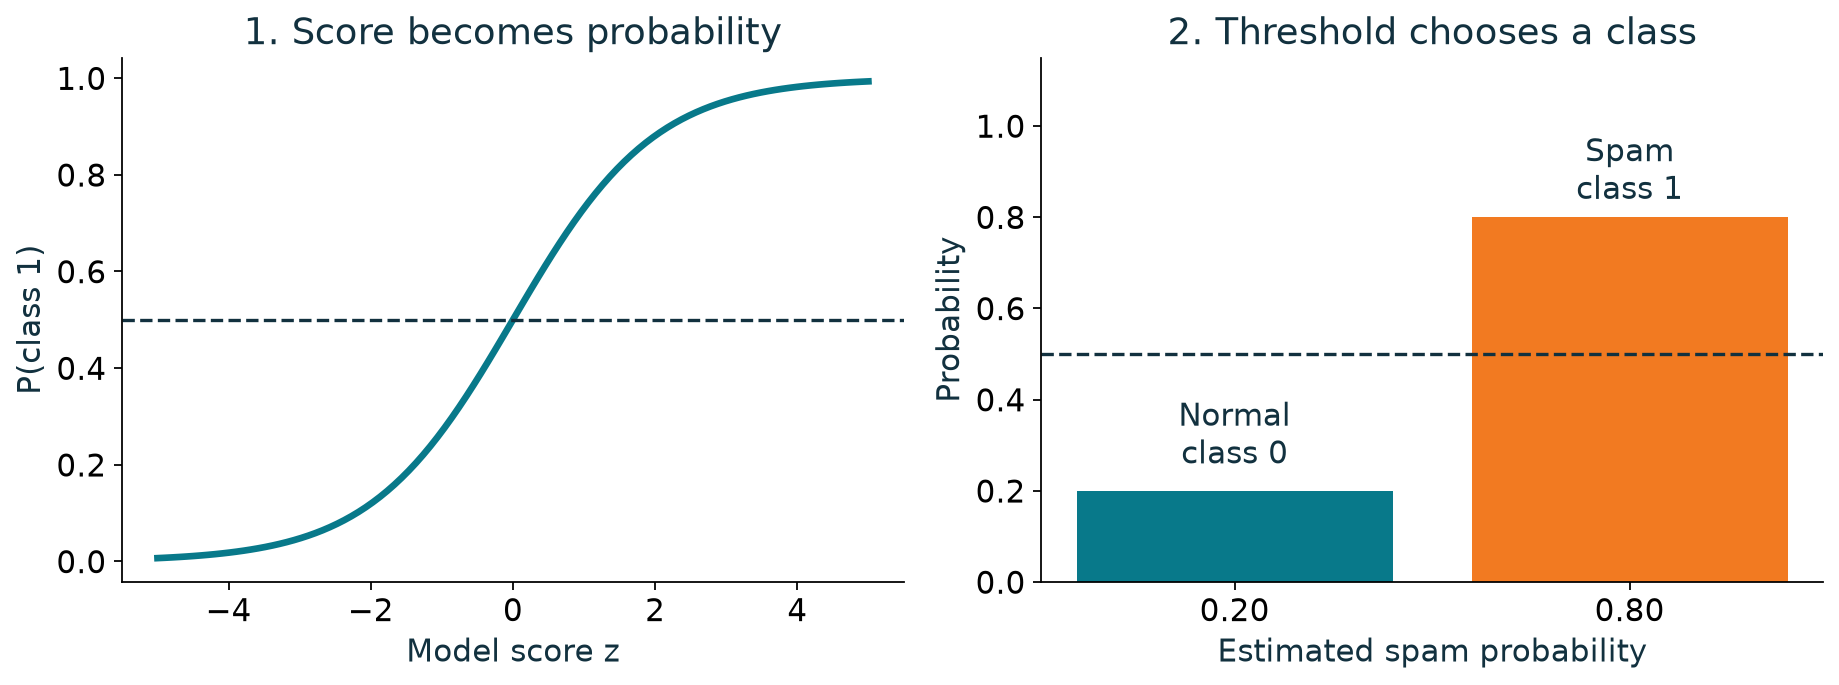

A sigmoid converts a score to a probability. With a 0.5 threshold, 0.20 is normal and 0.80 is spam.

## Load the examples

A **dataset** is a set of records. Each flower has petal measurements, called **features**, and a known species label, called the **target**. A **classification model** predicts a class label. We keep two species so each prediction is class 0 or class 1.

In [5]:
# 2. Load the table. The full dataset has 150 flowers and three species.
iris = load_iris(as_frame=True)

![isin([1, 2]) keeps versicolor and virginica. The selected old labels 1 and 2 are then renamed to 0 and 1.](attachment:flower_filter.png)

isin([1, 2]) keeps versicolor and virginica. The selected old labels 1 and 2 are then renamed to 0 and 1.
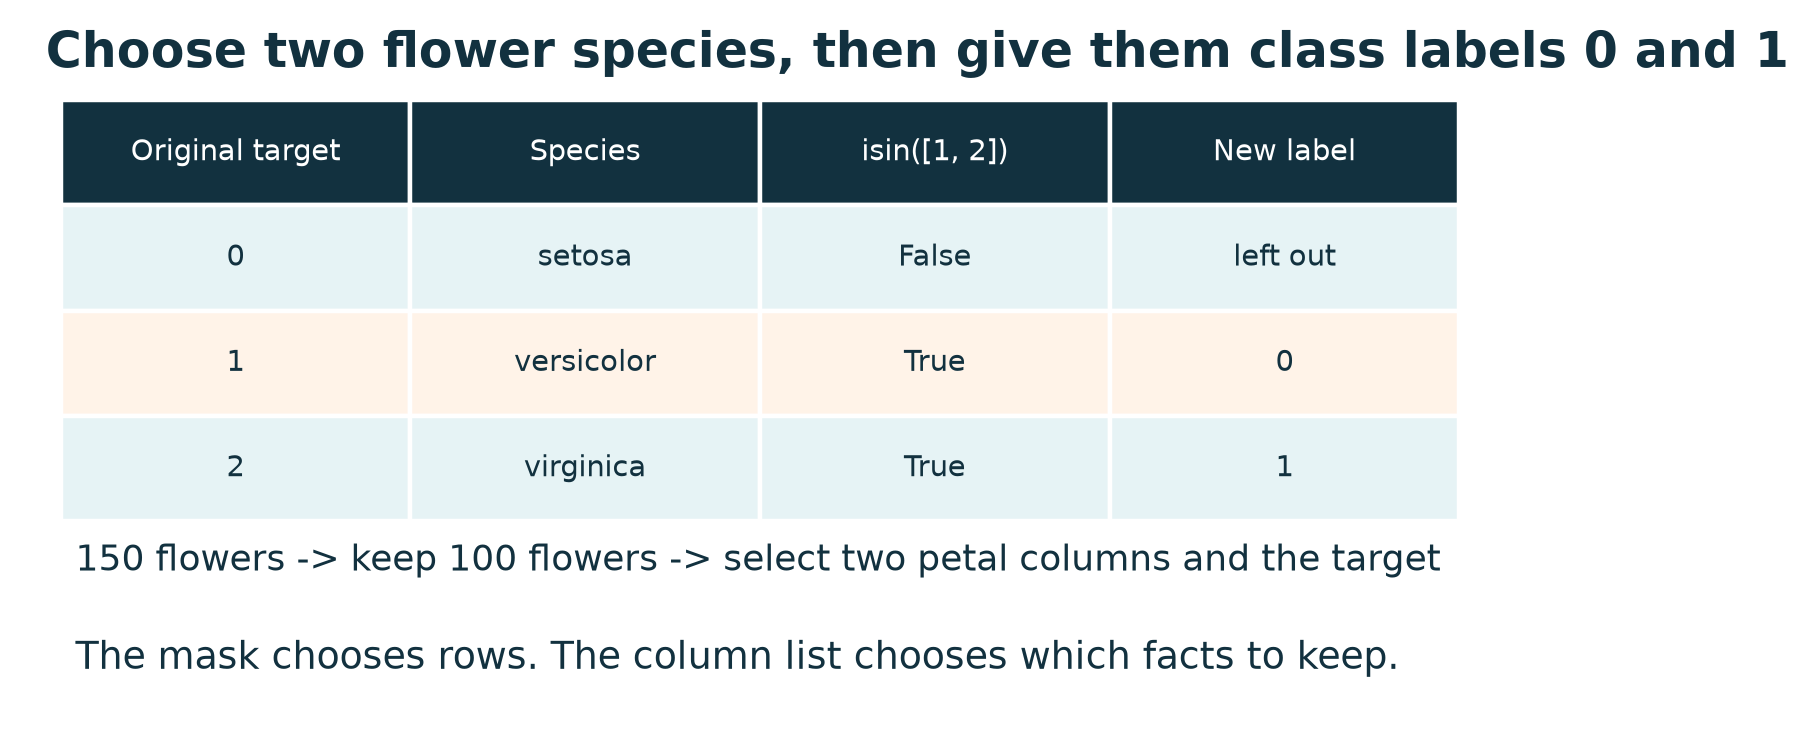

In [6]:
# isin() gives one True/False answer per flower. Keep old targets 1 and 2.
flower_mask = iris.frame['target'].isin([1, 2])

In [7]:
# A list names the two features and their target column.
flower_columns = ['petal length (cm)', 'petal width (cm)', 'target']

In [8]:
# loc selects matching rows and named columns. copy() creates a separate table.
data = iris.frame.loc[flower_mask, flower_columns].copy()

In [9]:
# Set class 0 = versicolor and class 1 = virginica.
data["target"] = data["target"].map({1: 0, 2: 1})

In [10]:
# Look at five rows. Petal measurements are in centimeters.
data.head()

,petal length (cm),petal width (cm),target
50,4.7,1.4,0
51,4.5,1.5,0
52,4.9,1.5,0
53,4.0,1.3,0
54,4.6,1.5,0


In [11]:
# Check rows and columns: 100 flowers, two features, and one target.
data.shape

(100, 3)

In [12]:
# Check types and non-missing counts.
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 50 to 149
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   petal length (cm)  100 non-null    float64
 1   petal width (cm)   100 non-null    float64
 2   target             100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [13]:
# This sample has no missing values, so no filling step is needed.
data.isna().sum()

petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

In [14]:
# Inspect repeated measurements; do not delete real flowers just because values match.
data.duplicated().sum()

np.int64(19)

In [15]:
# Confirm both classes have examples.
data["target"].value_counts().sort_index()

target
0    50
1    50
Name: count, dtype: int64

In [16]:
# Check the measurement ranges.
data.describe().round(2)

,petal length (cm),petal width (cm),target
count,100.00,100.00,100.0
mean,4.91,1.68,0.5
std,0.83,0.42,0.5
min,3.00,1.00,0.0
25%,4.38,1.30,0.0
50%,4.90,1.60,0.5
75%,5.52,2.00,1.0
max,6.90,2.50,1.0


In [17]:
# 3. X is the input table: two measured petal features.
X = data[["petal length (cm)", "petal width (cm)"]]

In [18]:
# y is the known class for each flower.
y = data["target"]

In [19]:
# Import the split tool.
from sklearn.model_selection import train_test_split

## Keep some records for a fair check

**Training records** teach the model. **Test records** are kept out of training and used to check predictions. `train_test_split()` divides inputs and their matching targets together. `test_size=0.2` sets aside about 20%. `random_state=42` fixes the shuffle so this example can be repeated. If `stratify=y` is used, it keeps the class shares close to those in the full dataset.

In [20]:
# Test 20%; seed 42 repeats the split; stratify keeps both classes in each part.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [21]:
# Confirm the split.
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 80 | Test rows: 20


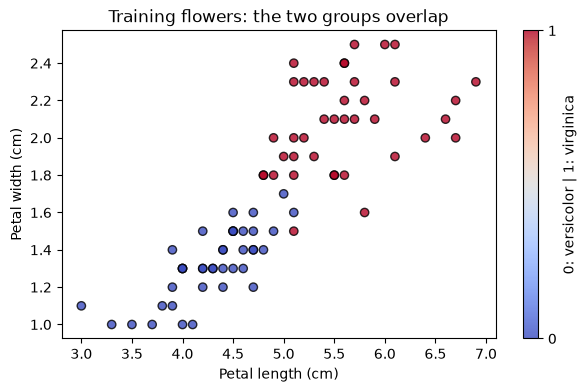

In [22]:
# 4. EDA: blue and red dots are two known species in the training data.
plt.figure(figsize=(7, 4))
plt.scatter(X_train["petal length (cm)"], X_train["petal width (cm)"], c=y_train, cmap="coolwarm", edgecolors="black", alpha=0.8)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Training flowers: the two groups overlap")
plt.colorbar(ticks=[0, 1], label="0: versicolor | 1: virginica")
plt.show()

In [23]:
# Compare training measurements by class. Virginica petals are larger on average here.
X_train.groupby(y_train).mean().round(2)

,petal length (cm),petal width (cm)
target,,
0,4.29,1.32
1,5.59,2.08


In [24]:
# Import scaling before using it. It puts each feature on a comparable scale.
from sklearn.preprocessing import StandardScaler

In [25]:
# A pipeline keeps the same scaling steps for training and prediction.
from sklearn.pipeline import make_pipeline

In [26]:
# Import the classifier before using it.
from sklearn.linear_model import LogisticRegression

## Create and fit the model

**LogisticRegression** learns scores, converts them to probabilities, and chooses a class. Scaling puts feature values on comparable scales. `max_iter=1000` allows enough fitting steps for this small example; fitting can finish earlier.

Creating the model sets up its settings. `fit()` supplies the training examples.

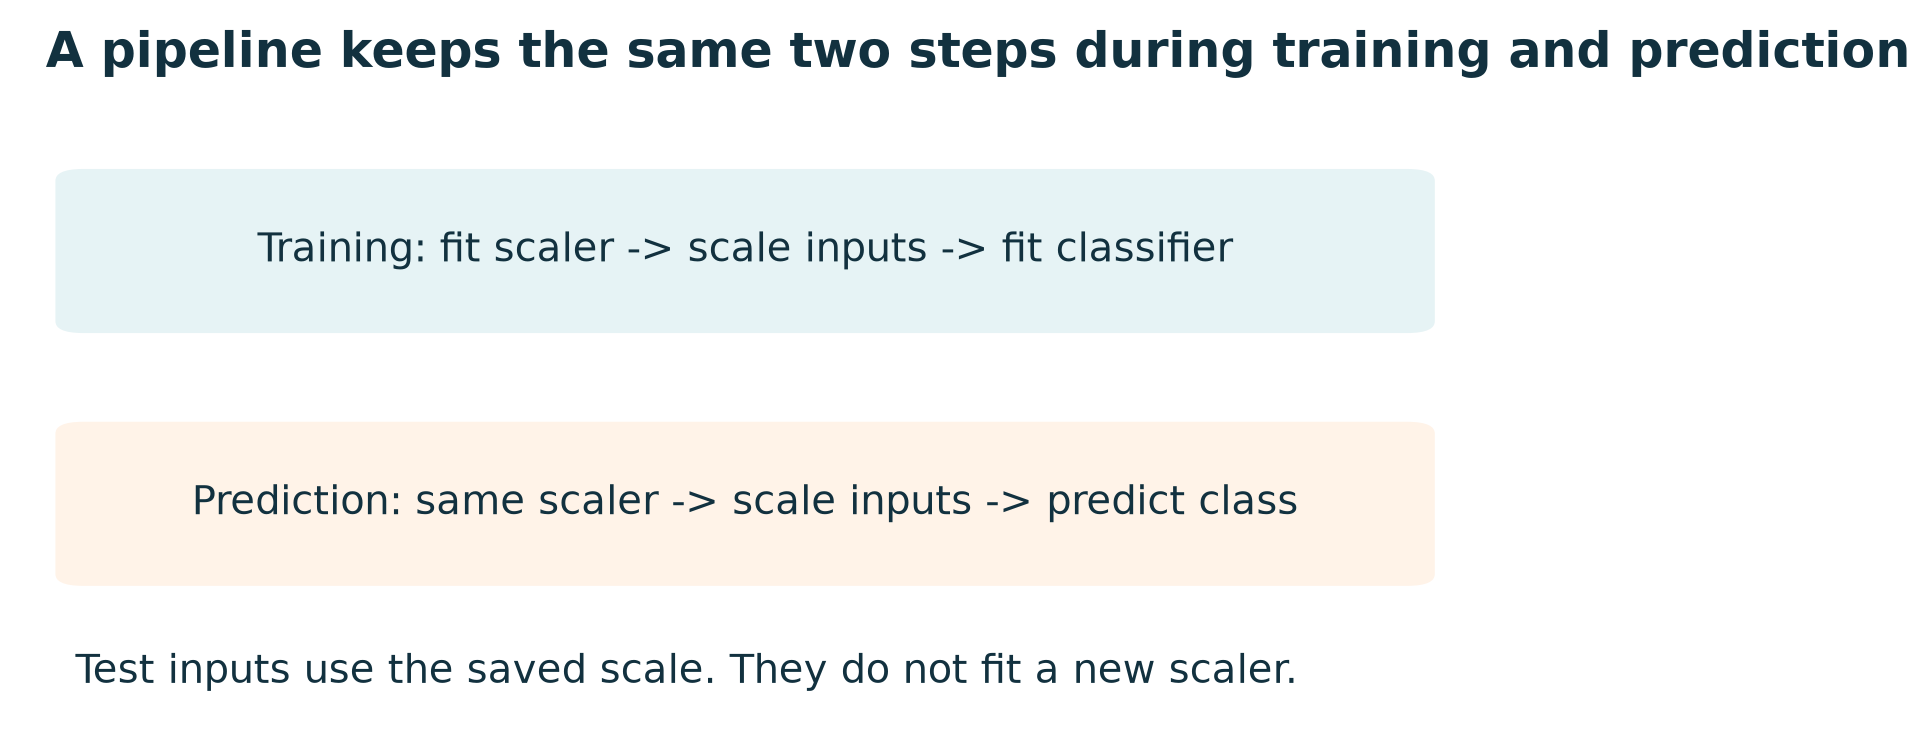

make_pipeline() links scaling and classification. fit learns from training rows. predict applies the saved steps to new inputs.

In [27]:
# A pipeline applies scaling before the classifier.
# fit() learns both steps using only training rows; predict() reuses the learned scale.
# 5. Scale first, then fit. 1000 is the maximum number of fitting steps.
logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

In [28]:
# fit() learns the model values using inputs X_train and known answers y_train.
# Learn the scale and model weights from training rows only.
logistic.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [29]:
# 6. Predict classes from test inputs, without seeing test answers.
y_pred = logistic.predict(X_test)

![These are example probabilities. [:, 1] selects column position 1 from every row; class order is given by classes_.](attachment:probability_columns.png)

These are example probabilities. [:, 1] selects column position 1 from every row; class order is given by classes_.
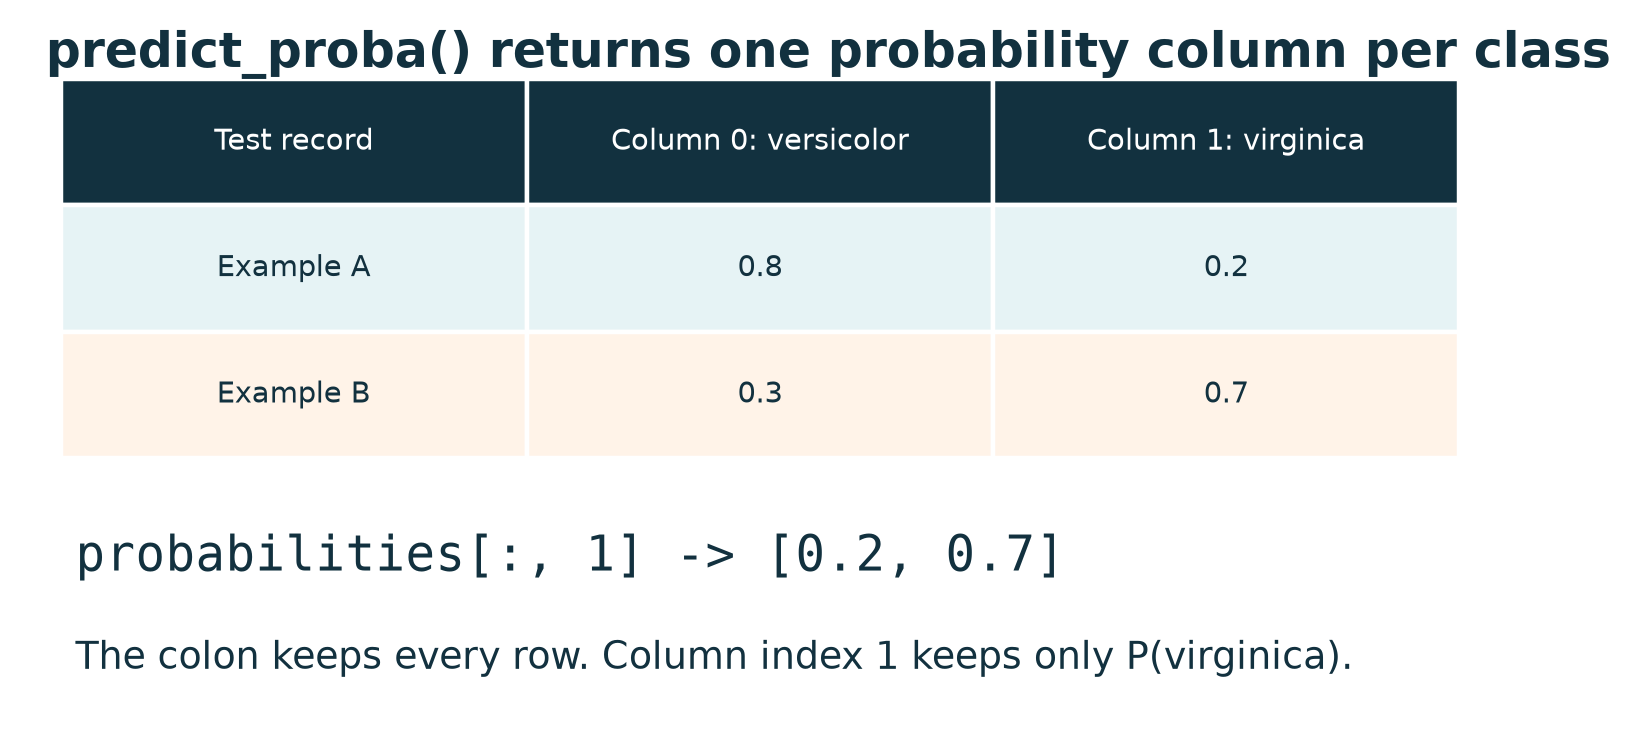

In [30]:
# predict_proba() returns both class probabilities for every test input.
probabilities = logistic.predict_proba(X_test)

In [31]:
# The colon keeps all rows. Column position 1 is P(virginica).
virginica_probability = probabilities[:, 1]

In [32]:
# Read actual class, predicted class, and probability for the same flowers.
results = pd.DataFrame({"Actual": y_test, "Predicted": y_pred, "P(virginica)": virginica_probability.round(3)})

In [33]:
# Inspect the first five test predictions.
results.head()

,Actual,Predicted,P(virginica)
107,1,1,0.977
127,1,1,0.648
113,1,1,0.872
101,1,1,0.832
57,0,0,0.001


In [34]:
# 7. Import the classification metrics.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

## Measure the test predictions

**Accuracy** is the share of correct labels. **Precision** asks how many predicted positive cases were right. **Recall** asks how many actual positive cases were found. **F1** combines precision and recall. Here class 1 means virginica.

In [35]:
# Accuracy counts correct predictions across both classes.
accuracy = accuracy_score(y_test, y_pred)

In [36]:
# Precision checks positive calls. Class 1 is virginica.
precision = precision_score(y_test, y_pred, zero_division=0)

In [37]:
# Recall checks how many real virginica flowers were found.
recall = recall_score(y_test, y_pred, zero_division=0)

In [38]:
# F1 combines precision and recall for virginica.
f1 = f1_score(y_test, y_pred, zero_division=0)

In [39]:
# Read all four final test metrics.
pd.Series({"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1}).round(3)

Accuracy     0.850
Precision    0.889
Recall       0.800
F1           0.842
dtype: float64

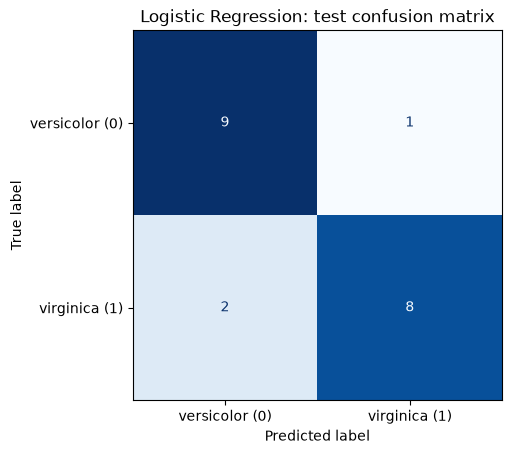

In [40]:
# Rows are actual classes; columns are predicted classes. The diagonal is correct.
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0, 1], display_labels=["versicolor (0)", "virginica (1)"], cmap="Blues", colorbar=False)
plt.title("Logistic Regression: test confusion matrix")
plt.show()